# TOPIC: NIGERIA'S ECONOMIC GROWTH AND MACROECONOMIC INDICATORS


## 1. INTRODUCTION
### RESEARCH MOTIVATION:
This study evaluates whether economic growth in Nigeria serves as an effective engine for job creation. While GDP growth is often cited as a benchmark for national success, its real impact on the population depends on how it interacts with key macroeconomic variables.

### CORE RESEARCH QUESTION:
### Does national economic growth actually translate into improved employment outcomes for Nigerians?

## 2. PROJECT OBJECTIVE:

* Track Macro Economic Trends: Analyze historical patterns in Nigeria's GDP growth and unemployment rates.

* Assess Employment Dynamics: Evaluate whether GDP growth is significantly associated with changes in the unemployment rate.

* Measure Commodity Impact: Examine how global oil price movements influence Nigeria's total economic output.

* Evaluate Demographic Factors: Investigate the relationship between population growth and aggregate GDP.

* Analyze Currency Effects: Explore how fluctuations in foreign exchange rates correspond to GDP changes.

* Execute Statistical Modeling: Apply quantitative methods to determine the direction, strength, and significance of relationships among variables.

* Deliver Actionable Insights: Present data-driven conclusions to support further econometric research and evidence-based policy making.



## 3. DATA SOURCES AND VARIABLES

The analysis used historical economic data, primarily from the World Bank's World Development Indicators, alongside international oil-price data from the World Bank's Commodity Price Data (Pink Sheet).

The variables included:
* GDP
* GDP per capita
* Population
* Exchange rate
* Unemployment rate
* International oil prices

## 4. METHODOLOGICAL APPROACH (MAPPING OBJECTIVES TO MODELS)



## Methodological Approach (Mapping Objectives to Models)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import wbdata as wb
import wbgapi as wb1
import requests as r
import seaborn as sns
from scipy.stats import pearsonr
import statsmodels.api as sm

FETCHING DATA FROM WORLDBANK API (wbgapi)

In [3]:
#wb1.source.info() to check the on segment topics
#wb1.series.info() information on indicators
#wb1.economy.info() information on countries economic and codes
#wb1.series.info(wb1.topic.members(8))
#wb1.series.info(q="women") to querrry keywords in the series
#wb1.economy.info(q='nigeria') to querrr keywords for countries
#wb1.search("gdp") to search for keywords in the whole database
indicator= ["SP.POP.TOTL",
            "NY.GDP.MKTP.CD",
            "NY.GDP.PCAP.CD",
            "PA.NUS.FCRF",
            "SL.UEM.TOTL.ZS"]
df= wb1.data.DataFrame(indicator,
                        "NGA", 
                        labels=True,
                        columns='series').reset_index()
df.head(5)


,time,Time,NY.GDP.MKTP.CD,NY.GDP.PCAP.CD,PA.NUS.FCRF,SL.UEM.TOTL.ZS,SP.POP.TOTL
0,YR2025,2025,2.907944e+11,1224.254102,1518.380948,3.064,237527782.0
1,YR2024,2024,2.522619e+11,1084.160418,1478.965197,3.045,232679478.0
2,YR2023,2023,4.873878e+11,2138.763837,645.194068,3.074,227882945.0
3,YR2022,2022,6.469503e+11,2899.160475,425.979158,3.827,223150896.0
4,YR2021,2021,6.091477e+11,2787.487792,401.152029,5.404,218529286.0


RENAMING COLUMNS

In [4]:
# renaming columns= {"SP.POP.TOTL":"Population",
#                    "NY.GDP.MKTP.CD":"GDP",
#                    "NY.GDP.PCAP.CD": "GDP_per_Capita",
#                    "PA.NUS.FCRF":"Exchange_Rate",
#                    "SL.UEM.TOTL.ZS":"Unemployment_Rate"   }
df.rename(columns={"SP.POP.TOTL":"Population",
                "NY.GDP.MKTP.CD":"GDP",
                "NY.GDP.PCAP.CD": "GDP_per_Capita",
                "PA.NUS.FCRF":"Exchange_Rate",
                "SL.UEM.TOTL.ZS":"Unemployment_Rate" }, inplace=True)
df.head(5)

,time,Time,GDP,GDP_per_Capita,Exchange_Rate,Unemployment_Rate,Population
0,YR2025,2025,2.907944e+11,1224.254102,1518.380948,3.064,237527782.0
1,YR2024,2024,2.522619e+11,1084.160418,1478.965197,3.045,232679478.0
2,YR2023,2023,4.873878e+11,2138.763837,645.194068,3.074,227882945.0
3,YR2022,2022,6.469503e+11,2899.160475,425.979158,3.827,223150896.0
4,YR2021,2021,6.091477e+11,2787.487792,401.152029,5.404,218529286.0


In [5]:
#Getting information about the table
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 66 entries, 0 to 65
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   time               66 non-null     str    
 1   Time               66 non-null     str    
 2   GDP                66 non-null     float64
 3   GDP_per_Capita     66 non-null     float64
 4   Exchange_Rate      66 non-null     float64
 5   Unemployment_Rate  35 non-null     float64
 6   Population         66 non-null     float64
dtypes: float64(5), str(2)
memory usage: 3.7 KB


ADDING WORLD OIL PRICE GOTTEN FROM WOLRD BANK

In [6]:
# Opening excel data on oil price in barrels gotten from world bank
oil=pd.read_excel("Data/CMO-Historical-Data-Annual.xlsx",
              sheet_name="Annual Prices (Nominal)",
              header=6)
# cleaning the data
oil= oil.iloc[1:].reset_index(drop=True)


In [7]:
# Inspecting the world oil price data
oil.info()

<class 'pandas.DataFrame'>
RangeIndex: 66 entries, 0 to 65
Data columns (total 70 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Unnamed: 0                    66 non-null     float64
 1   Crude oil, average            66 non-null     object 
 2   Crude oil, Brent              66 non-null     object 
 3   Crude oil, Dubai              66 non-null     object 
 4   Crude oil, WTI                66 non-null     object 
 5   Coal, Australian              66 non-null     object 
 6   Coal, South African           66 non-null     object 
 7   Natural gas, US               66 non-null     object 
 8   Natural gas, Europe           66 non-null     object 
 9   Liquefied natural gas, Japan  66 non-null     object 
 10  Natural gas index             66 non-null     object 
 11  Cocoa                         66 non-null     object 
 12  Coffee, Arabica               66 non-null     object 
 13  Coffee, Robusta   

In [8]:
#converting Time column into int for better analyses
df["Time"]= df["Time"].astype("int64")

# converting Unname as into int

oil["Unnamed: 0"]= oil["Unnamed: 0"].astype("int64")
# converting "Crude oil, Brent" into float
oil["Crude oil, Brent"]= oil["Crude oil, Brent"].astype("float")

In [9]:
# merged oil table with the df table 
df = df.merge(
    oil[["Unnamed: 0", "Crude oil, Brent"]],
    left_on="Time",
    right_on="Unnamed: 0",
    how="left"
).drop(columns="Unnamed: 0")

df.head()

,time,Time,GDP,GDP_per_Capita,Exchange_Rate,Unemployment_Rate,Population,"Crude oil, Brent"
0,YR2025,2025,2.907944e+11,1224.254102,1518.380948,3.064,237527782.0,69.0
1,YR2024,2024,2.522619e+11,1084.160418,1478.965197,3.045,232679478.0,80.7
2,YR2023,2023,4.873878e+11,2138.763837,645.194068,3.074,227882945.0,82.6
3,YR2022,2022,6.469503e+11,2899.160475,425.979158,3.827,223150896.0,99.8
4,YR2021,2021,6.091477e+11,2787.487792,401.152029,5.404,218529286.0,70.4


In [10]:
# rename colum 'Crude oil, Brent':Oil_price
df.rename(columns={"Crude oil, Brent":"Oil_price"},inplace=True)

In [11]:
# checking duplicates in the rows
display(f"Numbers of duplicates:{df.duplicated().sum()}")
# checking for nulls
print(f"Nulls in each columns:\n {df.isnull().sum()}",)

'Numbers of duplicates:0'

Nulls in each columns:
 time                  0
Time                  0
GDP                   0
GDP_per_Capita        0
Exchange_Rate         0
Unemployment_Rate    31
Population            0
Oil_price             0
dtype: int64


# Exploring the data

In [12]:
# Sorting the table df
df_sort= df.sort_values("Time")
df_sort.head(5)


,time,Time,GDP,GDP_per_Capita,Exchange_Rate,Unemployment_Rate,Population,Oil_price
65,YR1960,1960,4.196175e+09,93.137009,0.714286,NaN,45053782.0,1.6
64,YR1961,1961,4.467288e+09,97.137528,0.714286,NaN,45989310.0,1.6
63,YR1962,1962,4.909399e+09,104.532496,0.714286,NaN,46965292.0,1.5
62,YR1963,1963,5.165590e+09,107.675741,0.714286,NaN,47973575.0,1.5
61,YR1964,1964,5.552931e+09,113.297346,0.714286,NaN,49012016.0,1.5


In [13]:
# Getting the percentage changes in GDP as the year goes by
df_sort["GDP_growth"]= df_sort["GDP"].pct_change()* 100

# Getting the differences changes in Unemployment as the year goes by -
# we use .diff() because Unemployment rate is in percentage
df_sort["Unemployment_change"]= df_sort["Unemployment_Rate"].diff()

df_sort.tail(5)

,time,Time,GDP,GDP_per_Capita,Exchange_Rate,Unemployment_Rate,Population,Oil_price,GDP_growth,Unemployment_change
4,YR2021,2021,6.091477e+11,2787.487792,401.152029,5.404,218529286.0,70.4,1.764305,-0.310
3,YR2022,2022,6.469503e+11,2899.160475,425.979158,3.827,223150896.0,99.8,6.205808,-1.577
2,YR2023,2023,4.873878e+11,2138.763837,645.194068,3.074,227882945.0,82.6,-24.663790,-0.753
1,YR2024,2024,2.522619e+11,1084.160418,1478.965197,3.045,232679478.0,80.7,-48.242061,-0.029
0,YR2025,2025,2.907944e+11,1224.254102,1518.380948,3.064,237527782.0,69.0,15.274794,0.019


In [14]:
df_sort.describe(include="all")

,time,Time,GDP,GDP_per_Capita,Exchange_Rate,Unemployment_Rate,Population,Oil_price,GDP_growth,Unemployment_change
count,66,66.000000,6.600000e+01,66.000000,66.000000,35.000000,6.600000e+01,66.000000,65.000000,34.000000
unique,66,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,YR1960,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,1992.500000,1.762061e+11,1136.947955,129.004030,4.002886,1.171740e+08,34.756061,11.276084,-0.022559
std,NaN,19.196354,1.941481e+11,925.777289,276.096870,0.599442,5.810940e+07,32.238797,32.217770,0.347143
min,NaN,1960.000000,4.196175e+09,93.137009,0.546781,3.045000,4.505378e+07,1.200000,-72.920929,-1.577000
25%,NaN,1976.250000,3.610378e+10,469.283408,0.714286,3.746500,6.575215e+07,11.850000,-5.747530,-0.045750
50%,NaN,1992.500000,7.365183e+10,754.136496,19.591425,3.831000,1.037474e+08,24.050000,8.957035,-0.005500
75%,NaN,2008.750000,2.876610e+11,1822.235652,144.882006,4.053500,1.609359e+08,54.400000,24.399805,0.124750


### DATA VISUALIZATION

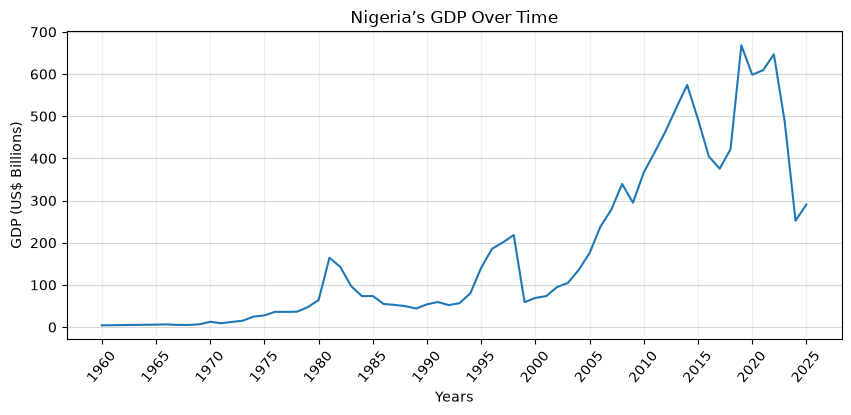

In [15]:
# visualizing the trend of growth (GDP) by time
years= df_sort['Time'].tolist()
# creating new columns to contain the figures


plt.figure(figsize=(10,4))

plt.plot(df_sort['Time'],df_sort['GDP']/1e9)
plt.xticks(years[::5],rotation=50)
plt.xlabel("Years")
plt.ylabel("GDP (US$ Billions)")
plt.title("Nigeria’s GDP Over Time")
plt.grid(axis="y", alpha=0.5)
plt.grid(axis='x', alpha=0.2)
plt.show()

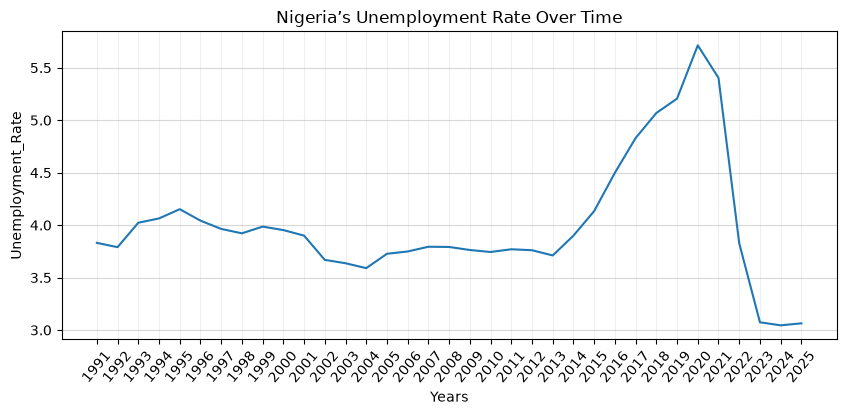

In [16]:
# visualizing the trend of Unemployment_Rate by time
unemployment_data= df_sort.iloc[~df_sort['Unemployment_Rate'].isnull()]
years= unemployment_data['Time'].tolist()
# creating new columns to contain the figures


plt.figure(figsize=(10,4))

plt.plot(unemployment_data['Time'],unemployment_data['Unemployment_Rate'])
plt.xticks(years[:],rotation=50)
plt.xlabel("Years")
plt.ylabel("Unemployment_Rate")
plt.title("Nigeria’s Unemployment Rate Over Time")
plt.grid(axis="y", alpha=0.5)
plt.grid(axis='x', alpha=0.2)
plt.show()

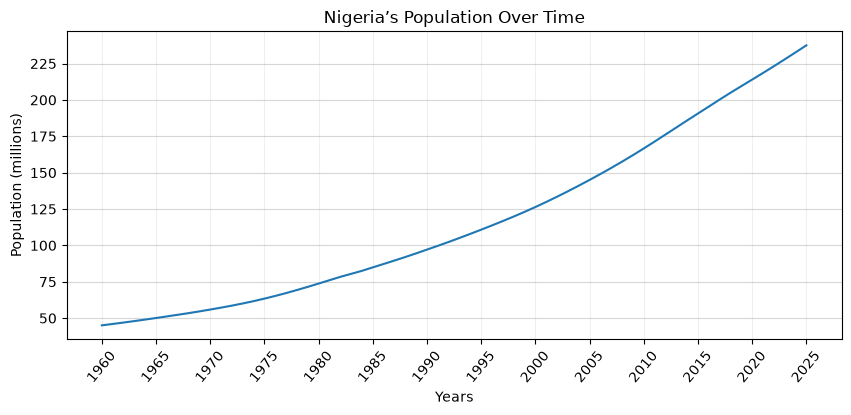

In [17]:
# visualizing the trend of growth (GDP) by time
years= df_sort['Time'].tolist()
# creating new columns to contain the figures


plt.figure(figsize=(10,4))

plt.plot(df_sort['Time'],df_sort["Population"]/1e6)
plt.xticks(years[::5],rotation=50)
plt.xlabel("Years")
plt.ylabel("Population (millions)")
plt.title("Nigeria’s Population Over Time")
plt.grid(axis="y", alpha=0.5)
plt.grid(axis='x', alpha=0.2)
plt.show()

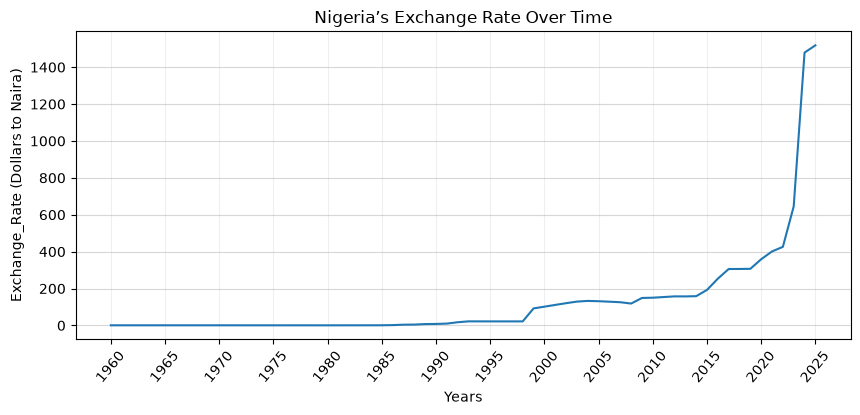

In [18]:
# visualizing the trend of Exchange_Rate by time
years= df_sort['Time'].tolist()
# Creating the chart
plt.figure(figsize=(10,4))

plt.plot(df_sort['Time'],df_sort["Exchange_Rate"])
plt.xticks(years[::5],rotation=50)
plt.xlabel("Years")
plt.ylabel("Exchange_Rate (Dollars to Naira)")
plt.title("Nigeria’s Exchange Rate Over Time")
plt.grid(axis="y", alpha=0.5)
plt.grid(axis='x', alpha=0.2)
plt.show()

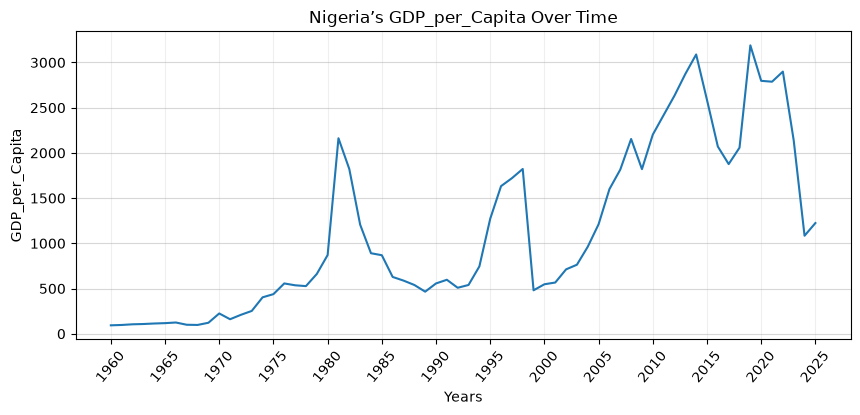

In [19]:
# visualizing GDP_per_Capita by time
years= df_sort['Time'].tolist()
# Creating the chart
plt.figure(figsize=(10,4))

plt.plot(df_sort['Time'],df_sort["GDP_per_Capita"])
plt.xticks(years[::5],rotation=50)
plt.xlabel("Years")
plt.ylabel("GDP_per_Capita")
plt.title("Nigeria’s GDP_per_Capita Over Time")
plt.grid(axis="y", alpha=0.5)
plt.grid(axis='x', alpha=0.2)
plt.show()

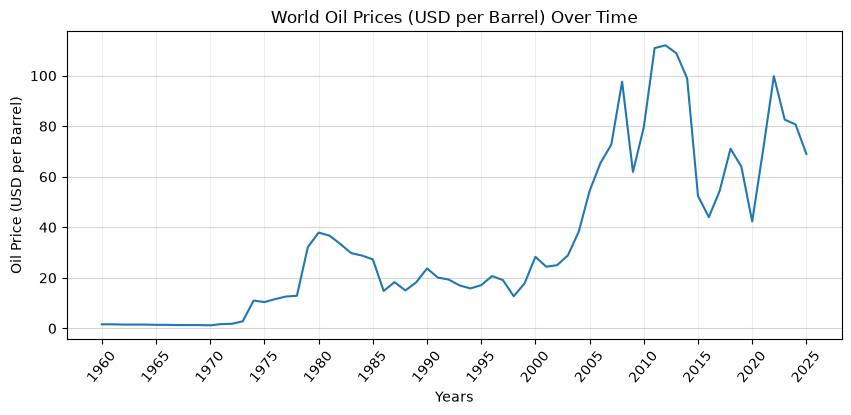

In [20]:
# visualizing the trend of Oil_price by time
years= df_sort['Time'].tolist()
# Creating the chart
plt.figure(figsize=(10,4))

plt.plot(df_sort['Time'],df_sort["Oil_price"])
plt.xticks(years[::5],rotation=50)
plt.xlabel("Years")
plt.ylabel("Oil Price (USD per Barrel)")
plt.title("World Oil Prices (USD per Barrel) Over Time")
plt.grid(axis="y", alpha=0.5)
plt.grid(axis='x', alpha=0.2)
plt.show()

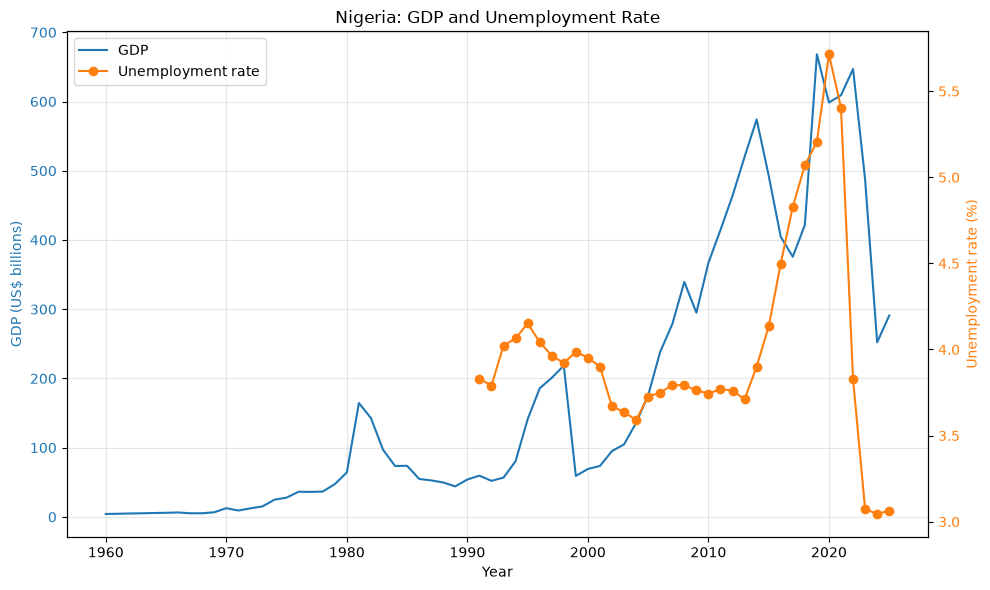

In [ ]:
# GDP and UNEMPLOYMENT RATE
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(df_sort["Time"], df_sort["GDP"] / 1e9, color="tab:blue", label="GDP")
ax1.set_xlabel("Year")
ax1.set_ylabel("GDP (US$ billions)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
unemployment_plot = unemployment_data.sort_values("Time")
ax2.plot(
    unemployment_plot["Time"],
    unemployment_plot["Unemployment_Rate"],
    color="tab:orange",
    marker="o",
    label="Unemployment rate",
)
ax2.set_ylabel("Unemployment rate (%)", color="tab:orange")
ax2.tick_params(axis="y", labelcolor="tab:orange")

ax1.set_title("Nigeria: GDP and Unemployment Rate")
ax1.grid(True, alpha=0.3)

lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [line.get_label() for line in lines], loc="upper left")

fig.tight_layout()
plt.show()

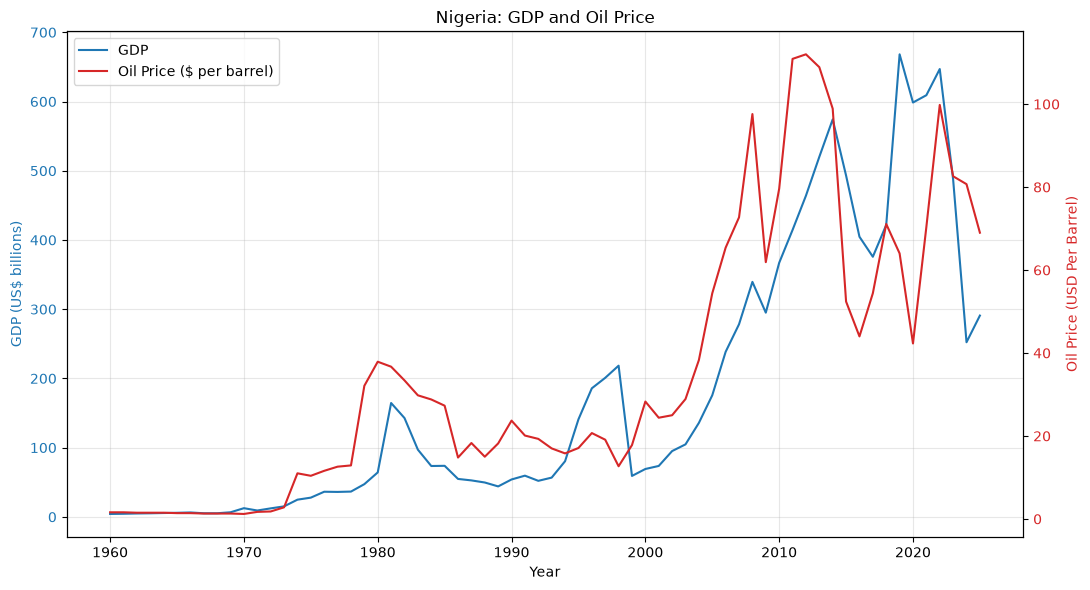

In [80]:
fig, ax1 = plt.subplots(figsize=(11,6))

ax1.plot(df_sort["Time"], df_sort["GDP"] / 1e9, color="tab:blue", label="GDP")
ax1.set_xlabel("Year")
ax1.set_ylabel("GDP (US$ billions)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
ax2.plot(
    df_sort["Time"],
    df_sort["Oil_price"],
    color="tab:red",
    label="Oil Price ($ per barrel)",
)
ax2.set_ylabel("Oil Price (USD Per Barrel)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

ax1.set_title("Nigeria: GDP and Oil Price")
ax1.grid(True, alpha=0.3)

lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [line.get_label() for line in lines], loc="upper left")

fig.tight_layout()
plt.show()

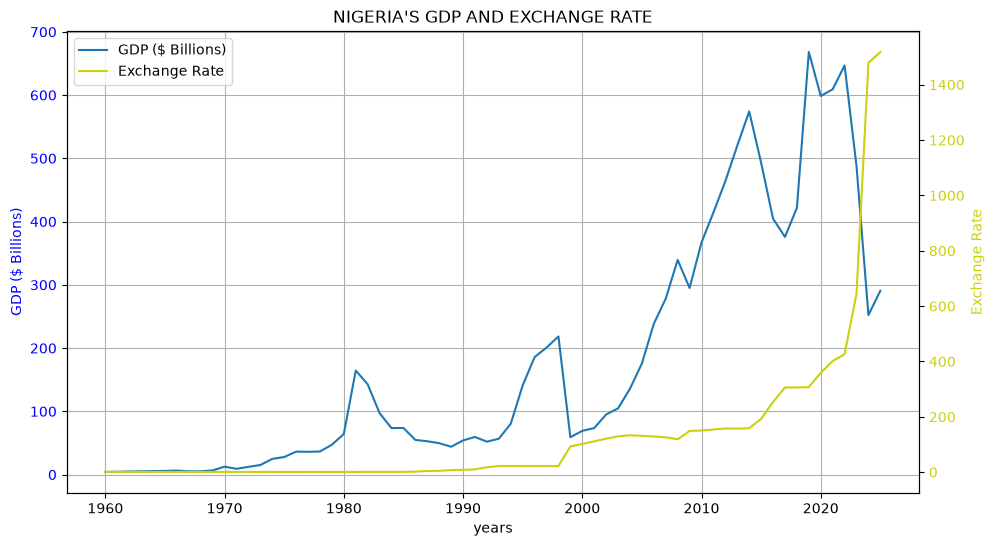

In [101]:
fig,ax1= plt.subplots(figsize=(11,6))

ax1.plot(df_sort["Time"],
         df_sort["GDP"]/1e9,
         label="GDP ($ Billions)")
ax2=ax1.twinx()

ax2.plot(df_sort["Time"],
          df_sort["Exchange_Rate"],
          label= "Exchange Rate",
          c="#CAD10D")
ax1.set_ylabel("GDP ($ Billions)", c="blue")
ax1.set_xlabel("years")
ax1.set_title("NIGERIA'S GDP AND EXCHANGE RATE")
ax1.tick_params(axis="y", labelcolor="blue")
ax1.grid()
ax2.set_ylabel("Exchange Rate", c="#CAD10D")
ax2.tick_params(axis="y", labelcolor="#CAD10D")
linees= ax1.get_lines() + ax2.get_lines()
ax1.legend(linees,[line.get_label() for line in linees], loc="upper left")


plt.show()

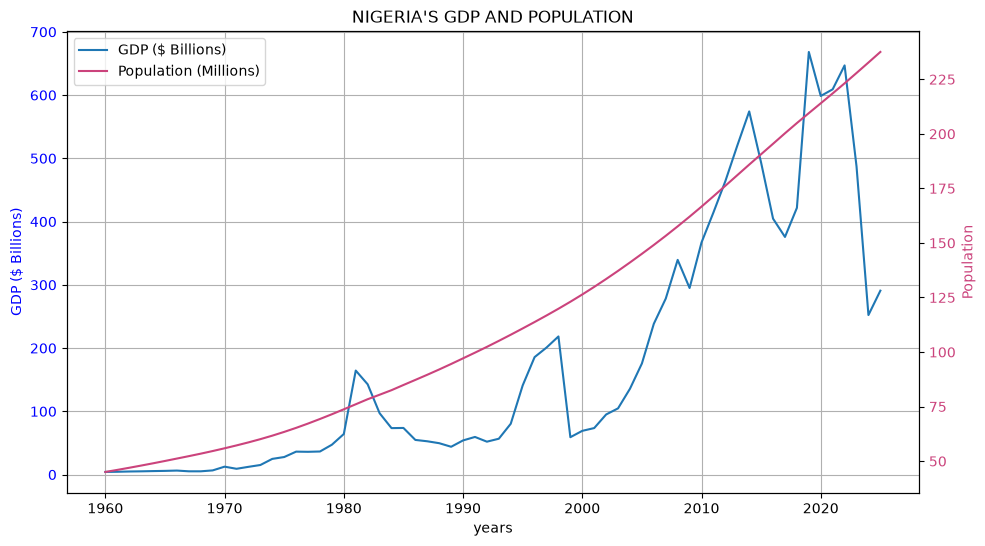

In [107]:
fig,ax1= plt.subplots(figsize=(11,6))

ax1.plot(df_sort["Time"],
         df_sort["GDP"]/1e9,
         label="GDP ($ Billions)")
ax2=ax1.twinx()

ax2.plot(df_sort["Time"],
          df_sort["Population"]/1e6,
          label= "Population (Millions)",
          c="#CB437C")
ax1.set_ylabel("GDP ($ Billions)", c="blue")
ax1.set_xlabel("years")
ax1.set_title("NIGERIA'S GDP AND POPULATION")
ax1.tick_params(axis="y", labelcolor="blue")
ax1.grid()
ax2.set_ylabel("Population", c="#CB437C")
ax2.tick_params(axis="y", labelcolor="#CB437C")
linees= ax1.get_lines() + ax2.get_lines()
ax1.legend(linees,[line.get_label() for line in linees], loc="upper left")


plt.show()

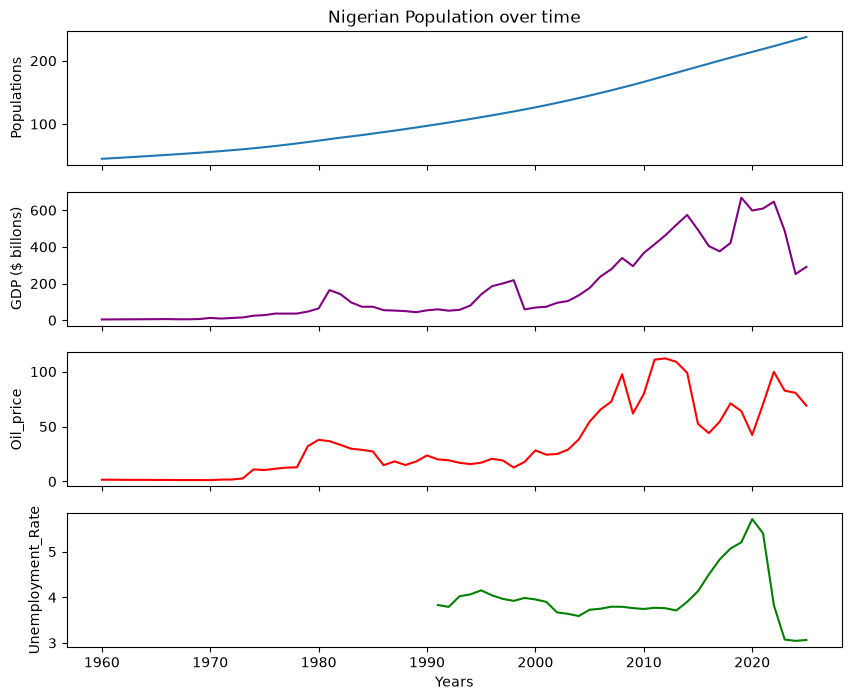

In [21]:
fig,axes= plt.subplots(4,1
                       ,figsize=(10,8), sharex=True)

axes[0].plot(df_sort["Time"],df_sort["Population"]/1e6)
axes[0].set_ylabel("Populations")
axes[0].set_title("Nigerian Population over time")

axes[1].plot(df_sort["Time"],df_sort["GDP"]/1e9, c='purple')
axes[1].set_ylabel("GDP ($ billons)")

axes[2].plot(df_sort["Time"],df_sort["Oil_price"], c="red")
axes[2].set_ylabel("Oil_price")

axes[3].plot(df_sort["Time"],df_sort["Unemployment_Rate"],c='green')
axes[3].set_ylabel("Unemployment_Rate")
axes[3].set_xlabel("Years")

plt.show()

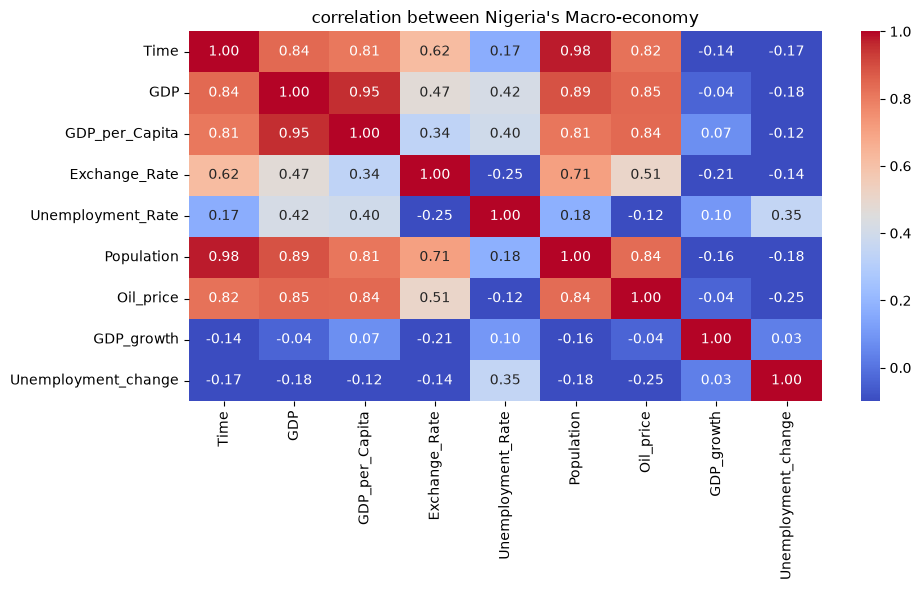

In [22]:
# Checking the corrolations among the varieble 
# that is innspecting the realationship betwwen the variebles

columns=df_sort.columns[1:]
correlation= df_sort[columns].corr()

plt.figure(figsize=(10,6))

sns.heatmap(correlation,
            annot=True,
            cmap="coolwarm",
            fmt=".2f",
            vmin=-.1,
            vmax=1)
plt.title("correlation between Nigeria's Macro-economy")
plt.tight_layout()
plt.show()

## STATISTICAL ANALYSIS

The above diagrame shows that the relationship between GDP and Unemployment rate is Moderate (that is not that strong). 
* we want to test is the relationship is valid and significant
* we use Pearson corrolation test (it also to check for two tail test)

### Hypothesis Questions
* h0 There is no relationship between- GDP and Unemploment
* h1 There is a relationship between- GDP and Unemploment
* confidence level 0.05 

CORRELATION ANALYSIS: RELATIONSHIP BETWEEN GDP AND UNEMPLOYMENT
Correlation Coefficient: 0.416
P_value: 0.013
Conclusion: Reject the null hypothesis. There is a statistically 
significant, moderate positive correlation between GDP and the unemployment rate


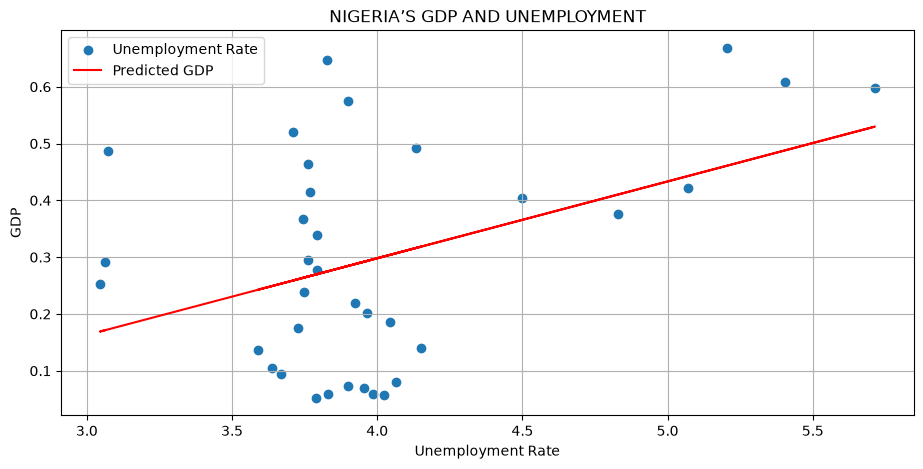

REGRESSION COEFFICIENTS AND THEIR STATISTICAL SIGNIFICANCE 
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -0.2427      0.208     -1.167      0.251      -0.666       0.180
Unemployment_Rate     0.1352      0.051      2.632      0.013       0.031       0.240


In [48]:
# Testing the effect that exist between GDP and Unemployment
# (building a model using stata)
# Teating the coefficient of the between GDP and oil price
print("============================================================================")
print("CORRELATION ANALYSIS: RELATIONSHIP BETWEEN GDP AND UNEMPLOYMENT")
print("============================================================================")
unemployment_data= df_sort.iloc[~df_sort['Unemployment_Rate'].isnull()]

# doing two tail test with pearson corrolation test
#  (That is relationship )betweeen GDP and Unemployment

r,p_value= pearsonr(unemployment_data["GDP"],
                    unemployment_data["Unemployment_Rate"])

print(f"Correlation Coefficient: {r:.3f}")
print(f"P_value: {p_value:.3f}")

alpha=0.05

if p_value<= alpha:
    print("Conclusion: Reject the null hypothesis. There is a statistically " \
    "\nsignificant, moderate positive correlation between GDP and the unemployment rate")
    
else:
    print("Accept the null hypothesis")
    print(f"There is no significant relationship (p_value:{p_value:.3f})")   
print("============================================================================")
x_unemploy= unemployment_data["Unemployment_Rate"]
y_unemploy= unemployment_data["GDP"]/1e12

x_unemploy= sm.add_constant(x_unemploy)
# fitting the model
model_unemploy= sm.OLS(y_unemploy,x_unemploy).fit()

# creating a scatter chart to show relationship
model_unempl_predict= model_unemploy.predict(x_unemploy)

plt.figure(figsize=(11,5))
plt.scatter(unemployment_data["Unemployment_Rate"],
            y_unemploy,
            label="Unemployment Rate")
plt.plot(unemployment_data["Unemployment_Rate"],
         model_unempl_predict, c="red", 
         label="Predicted GDP")

plt.title("NIGERIA’S GDP AND UNEMPLOYMENT")
plt.xlabel("Unemployment Rate")
plt.ylabel("GDP")
plt.legend()
plt.grid()

plt.show()

print("=====================================================================================")
print("REGRESSION COEFFICIENTS AND THEIR STATISTICAL SIGNIFICANCE ")
print("=====================================================================================")
print(model_unemploy.summary().tables[1])
print("=====================================================================================")


### INTERPRETATION
Correlation: The correlation coefficient ($r = 0.416$) shows a moderate positive linear correlation between the unemployment rate and GDP. Because the p-value is $0.013$ (less than $\alpha = 0.05$), we reject the null hypothesis and confirm that this correlation is statistically significant.

The analysis demonstrates a statistically significant positive association between higher unemployment rates and higher GDP values in this dataset. This highlights that increases in economic output do not automatically correspond to lower unemployment in Nigeria. However, as with all linear regressions, these results establish a statistical association rather than direct causation, and do not prove that higher unemployment causes GDP to increase.


## Testing the hypothesis of GDP_growth and Unemployment change
### (i.e Testing if GDP increment over time has a significant relationship or effect with unemployment rate)

CORRELATION ANALYSIS: GDP GROWTH VS. UNEMPLOYMENT CHANGE 
Correlation coefficient:0.031
P-value: 0.859905
Conclusion: Fail to reject the null hypothesis.
There is no statistically significant linear relationship 
between GDP growth and changes in the unemployment rate in this dataset.


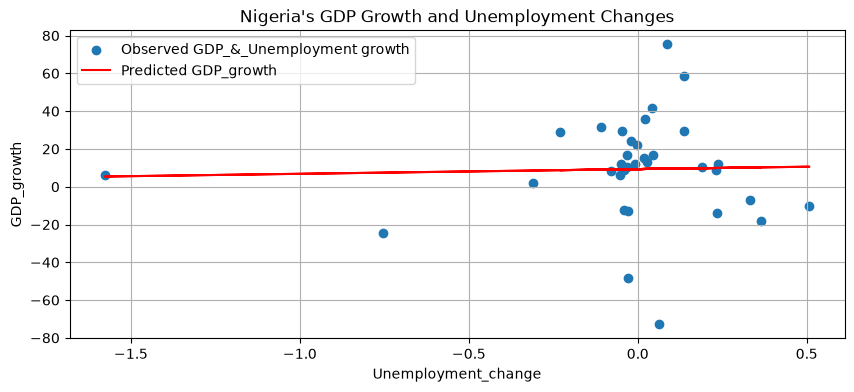

REGRESSION COEFFICIENT AND IT'S STATISTICAL SIGNIFICANCE
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   9.3335      4.806      1.942      0.061      -0.456      19.123
Unemployment_change     2.4949     14.022      0.178      0.860     -26.068      31.057


In [24]:
print("====================================================================================")
print("CORRELATION ANALYSIS: GDP GROWTH VS. UNEMPLOYMENT CHANGE ")
print("====================================================================================")

data_growth= df_sort[["GDP_growth","Unemployment_change"]].dropna()


r_growth,P_growth= pearsonr(data_growth["GDP_growth"],
                            data_growth["Unemployment_change"])

alpha=0.05

print(f"Correlation coefficient:{r_growth:.3f}")

if P_growth<= alpha:
    print(f"P-value: {P_growth:3f}")
    print("reject the null hypothesis")
else:
    print(f"P-value: {P_growth:3f}")
    print(f"Conclusion: Fail to reject the null hypothesis." 
          "\nThere is no statistically significant linear relationship " \
          "\nbetween GDP growth and changes in the unemployment rate in this dataset.")
print("========================================================================================")

x_growth= data_growth["Unemployment_change"]
y_growth= data_growth["GDP_growth"]

x_growth= sm.add_constant(x_growth)
# fitting the model
model_growth= sm.OLS(y_growth,x_growth).fit()

# creating a scatter chart to show relationship

plt.figure(figsize=(10,4))
plt.scatter(data_growth["Unemployment_change"],
            y_growth,
            label="Observed GDP_&_Unemployment growth")
plt.plot(data_growth["Unemployment_change"],
         model_growth.predict(x_growth),
         c="red", 
         label="Predicted GDP_growth")

plt.title("Nigeria's GDP Growth and Unemployment Changes")
plt.xlabel("Unemployment_change")
plt.ylabel("GDP_growth")
plt.legend()
plt.grid()

plt.show()

print("=====================================================================================")
print("REGRESSION COEFFICIENT AND IT'S STATISTICAL SIGNIFICANCE")
print(model_growth.summary().tables[1])
print("=====================================================================================")


INTERPRETATION
Correlation: The correlation coefficient ($r = 0.031$) indicates an extremely weak positive linear relationship between unemployment changes and GDP growth. Because the p-value is $0.859905$ (well above $\alpha = 0.05$), we fail to reject the null hypothesis, confirming there is no statistically significant linear relationship in this dataset.

The statistical analysis provides insufficient evidence to conclude that changes in unemployment are associated with GDP growth in Nigeria over the studied period. Changes in Nigeria’s GDP do not necessarily lead to immediate changes in formal unemployment rates.

# Testing the relation between GDP and oil price

CORRELATION VALUES (i.e RELATIONSHIP BETWEEN GDP AND OIL PRICE)
correlation_coefficient:0.847
p_value:0.000
Reject the null hypothesis because the p_value (0.00) is statistically significant


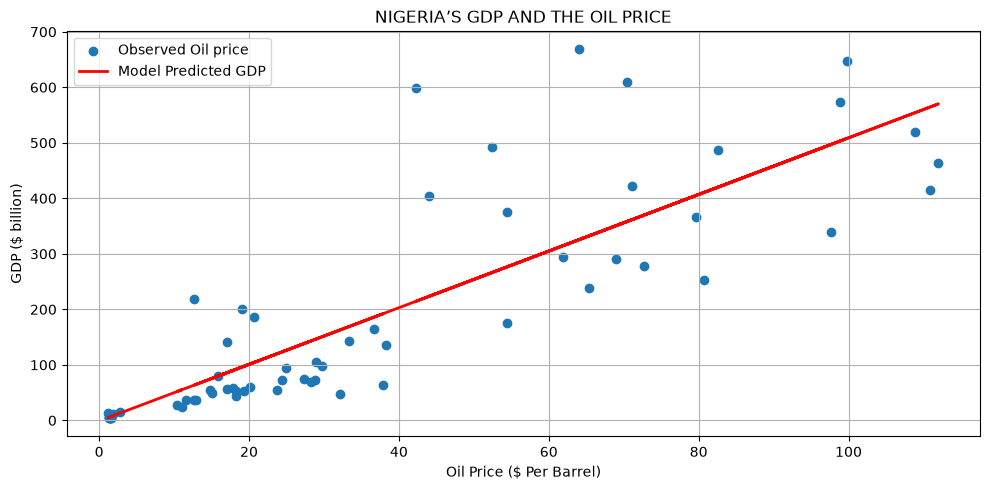

REGRESSION COEFFICIENT AND IT'S STATISTICAL SIGNIFICANCE
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.0776     18.904     -0.057      0.955     -38.842      36.687
Oil_price      5.1008      0.400     12.747      0.000       4.301       5.900


In [44]:
# Teating the coefficient of the between GDP and oil price
print("============================================================================")
print("CORRELATION VALUES (i.e RELATIONSHIP BETWEEN GDP AND OIL PRICE)")
print("============================================================================")

r_oil,p_oil= pearsonr(df_sort["GDP"]/1e9,
                      df_sort["Oil_price"])

print(f"correlation_coefficient:{r_oil:.3f}")
print(f"p_value:{p_oil:.3f}")
if p_oil > alpha:
    print(f"accept the null hypothesis for p_value {p_oil}is insignificant")
else:
    print(f"Reject the null hypothesis because the p_value ({p_oil:.2f}) is statistically significant")
    
print("============================================================================")

# Preparing the model for the chart
x_oil= df_sort["Oil_price"]
y_oIl= df_sort["GDP"]/1e9

x_oil= sm.add_constant(x_oil)

model_oil= sm.OLS(y_oIl,x_oil).fit()

# PLOTING THE GRAPH TO SHOW RELATIONSHIP
plt.figure(figsize=(10,5))
plt.scatter(df_sort["Oil_price"],
            y_oIl,
            label="Observed Oil price")

plt.plot(df_sort["Oil_price"],
         model_oil.predict(x_oil),
         color="red",
         linewidth=2,
         label="Model Predicted GDP")

plt.title( "NIGERIA’S GDP AND THE OIL PRICE")
plt.legend()
plt.grid()
plt.xlabel("Oil Price ($ Per Barrel)")
plt.ylabel("GDP ($ billion)")
plt.tight_layout()
plt.show()

print("==============================================================================")
print("REGRESSION COEFFICIENT AND IT'S STATISTICAL SIGNIFICANCE")
print("==============================================================================")
print(model_oil.summary().tables[1])
print("==============================================================================")

#### INTERPRETATION
Correlation: The correlation coefficient ($r = 0.847$) demonstrates a strong positive linear relationship between global oil prices and Nigeria's GDP. Because the p-value is $0.000$ (well below $\alpha = 0.05$).

The analysis proves a strong, statistically significant positive association between higher oil prices and expansion in Nigeria's aggregate GDP. However, this reflects a statistical relationship rather than direct causation, driven by the critical indirect role crude oil revenues play in supplying foreign exchange, funding public spending, and boosting broader macro liquidity in Nigeria.

## Testing the Relationship between GDP and Population

CORRELATION VALUES (i.e RELATIONSHIP BETWEEN GDP AND POPULATION)
correlation_coefficient:0.89
Reject the null hypothesis because the p-value is statistically significant(0.00)


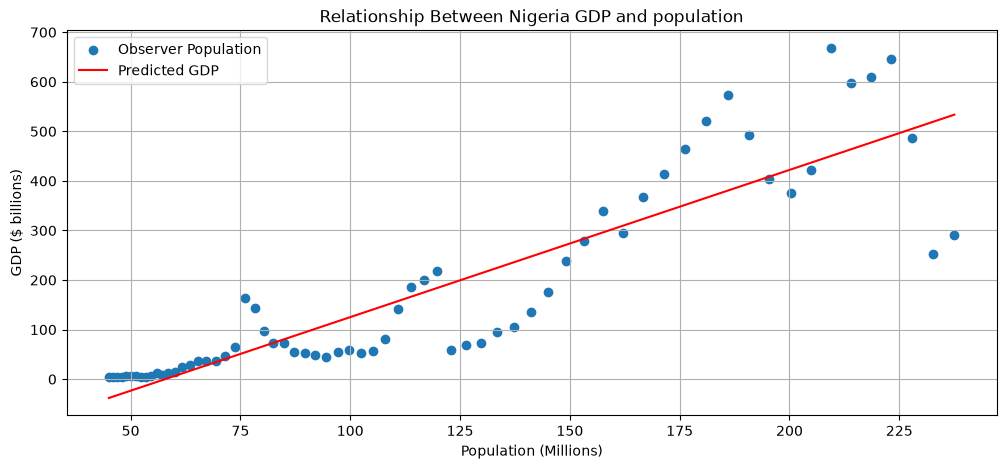

REGRESSION COEFFICIENT AND IT'S STATISTICAL SIGNIFICANCE
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -171.8367     24.972     -6.881      0.000    -221.724    -121.949
Population     2.9703      0.191     15.534      0.000       2.588       3.352


In [34]:
# Verifying the relationship between GDP and population
r_pop,p_value_pop= pearsonr(df_sort["GDP"],df_sort["Population"])

alpha=0.05
print("============================================================================")
print("CORRELATION VALUES (i.e RELATIONSHIP BETWEEN GDP AND POPULATION)")
print("============================================================================")

print(f"correlation_coefficient:{r_pop:.2f}")
if p_value_pop > alpha:
    print(f"accept the null hypothesis for p_value {p_value_pop}is insignificant")
else:
    print(f"Reject the null hypothesis because the p-value is statistically significant({p_value_pop:.2f})")
    
print("===========================================================================")

# create model for the graph
x_pop= df_sort["Population"]/1e6
y_pop= df_sort["GDP"]/1e9

x_pop= sm.add_constant(x_pop)
# fitting the model

model_pop= sm.OLS(y_pop,x_pop).fit()

# Creating the graph and scatter chat
plt.figure(figsize=(12,5))
plt.scatter(df_sort["Population"]/1e6,
            y_pop,
            label= "Observer Population")
plt.plot(df_sort["Population"]/1e6,
         model_pop.predict(x_pop),
         label= "Predicted GDP",
         c= "red")

plt.ylabel("GDP ($ billions)")
plt.xlabel("Population (Millions)")
plt.grid()
plt.legend()
plt.title("Relationship Between Nigeria GDP and population")
plt.show()

print("==========================================================================")
print("REGRESSION COEFFICIENT AND IT'S STATISTICAL SIGNIFICANCE")
print("==========================================================================")
print(model_pop.summary().tables[1])
print("==========================================================================")


#### INTERPRETATION
Correlation: The correlation coefficient ($r = 0.89$) demonstrates a strong positive linear relationship between population size and GDP. The p-value of $0.00$ allows us to reject the null hypothesis, confirming that this correlation is statistically significant.

The statistical results show a strong, statistically significant positive association between Nigeria's population growth and its overall GDP. However, this reflects a statistical association rather than direct causation, as population expansion and GDP output both naturally scale over time in growing national economies.


### TESTING THE RELATIONSHIP AND EFFECT BETWEEN GDP AND EXCHANGE RATE

CORRELATION VALUES (i.e RELATIONSHIP BETWEEN GDP AND EXCHANGE RATE)
correlation_coefficient:0.47
Reject the null value because the coefficient p_value (0.00) is statistically significant


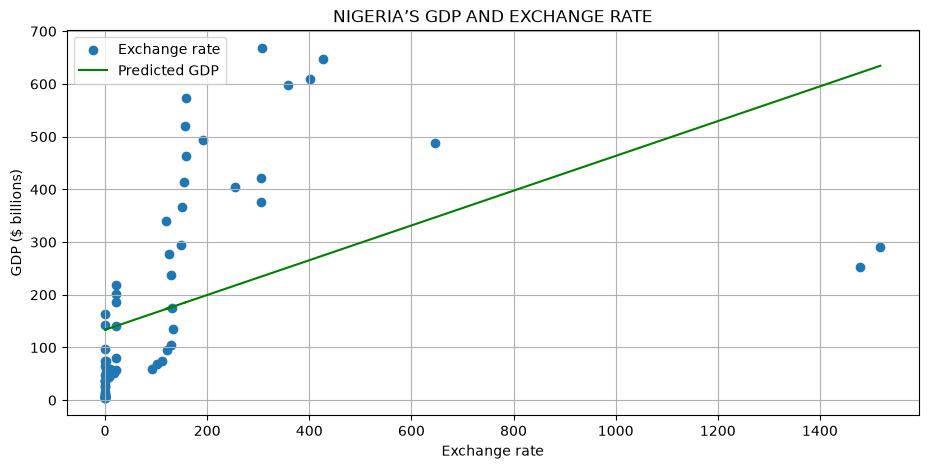

REGRESSION COEFFICIENT AND IT'S STATISTICAL SIGNIFICANCE
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const           133.6554     23.510      5.685      0.000      86.689     180.621
Exchange_Rate     0.3298      0.078      4.249      0.000       0.175       0.485


In [43]:
# Testing for correlation between GDP and exchange Rate
r_exr,p_exr= pearsonr(df_sort["GDP"],df_sort["Exchange_Rate"])

alpha=0.05
print("============================================================================")
print("CORRELATION VALUES (i.e RELATIONSHIP BETWEEN GDP AND EXCHANGE RATE)")
print("============================================================================")

print(f"correlation_coefficient:{r_exr:.2f}")
if p_exr > alpha:
    print(f"accept the null hypothesis for p_value {p_exr}is insignificant")
else:
    print(f"Reject the null value because the coefficient p_value ({p_exr:.2f}) is statistically significant")
    
print("===========================================================================")

# Creating the model for the graph and regression
x_exr= df_sort["Exchange_Rate"]
y_exr= df_sort["GDP"]/1e9

x_exr= sm.add_constant(x_exr)
#fitting the model
model_exr= sm.OLS(y_exr,x_exr).fit()

# Creating the scatter and line chat to show relationship
plt.figure(figsize=(11,5))
plt.scatter(df_sort["Exchange_Rate"],
            y_exr,
            label="Exchange rate")
plt.plot(df_sort["Exchange_Rate"],
         model_exr.predict(x_exr),
         label= "Predicted GDP",
         c="green")
plt.title("NIGERIA’S GDP AND EXCHANGE RATE")
plt.legend()
plt.xlabel("Exchange rate")
plt.ylabel("GDP ($ billions)")
plt.grid()

plt.show()

print("==============================================================================")
print("REGRESSION COEFFICIENT AND IT'S STATISTICAL SIGNIFICANCE")
print("==============================================================================")
print(model_exr.summary().tables[1])
print("==============================================================================")



#### INTERPRETATION
Correlation: The correlation coefficient ($r = 0.47$) shows a moderate positive linear relationship between the exchange rate and GDP. Because the p-value is $0.000$ (less than $\alpha = 0.05$), we reject the null hypothesis and conclude that this correlation is statistically significant

The statistical analysis demonstrates a statistically significant positive association between higher exchange rates and Nigeria's GDP. However, this result reflects a statistical association rather than direct causation, as macro trends over time (such as inflation, currency devaluation, and general nominal GDP expansion) often move simultaneously in developing economies.

### Multiple Regression 

In [52]:
# converting the null value in Unemployment to 0
#df_sort.loc[df_sort["Unemployment_Rate"].isna(), "Unemployment_Rate"] = 0
unemployment_data["Populations"]= unemployment_data["Population"]/1e6
variable_reg= unemployment_data[["Oil_price",
                       "Exchange_Rate",
                       "Unemployment_Rate",
                       "Populations"]]
x= sm.add_constant(variable_reg)
y= unemployment_data["GDP"]/1e9

# fitting to model
model= sm.OLS(y,x).fit()

print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                    GDP   R-squared:                       0.902
Model:                            OLS   Adj. R-squared:                  0.889
Method:                 Least Squares   F-statistic:                     68.78
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           1.13e-14
Time:                        19:15:18   Log-Likelihood:                -193.05
No. Observations:                  35   AIC:                             396.1
Df Residuals:                      30   BIC:                             403.9
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const              -632.2080     82.88